# EDA: Thunderbird

Исследование по 11 пунктам чеклиста. Данные приходят через Python-функцию из `util/loghub_systems.py`; вычисления вынесены в `util/loghub_eda.py`. Запуск: установить `requirements-eda-systems.txt`, выбрать это Python-окружение и выполнить **Restart Kernel → Run All**. Порядок ячеек самодостаточен.

Область анализа явно отмечена: полный поток и случайная выборка не смешиваются. Числа в таблицах вычисляются из данных, пропуски и ограничения сохраняются.

## 1. Происхождение данных

Системные логи суперкомпьютера Thunderbird в Sandia National Labs, Albuquerque: 9 024 процессора. Это **не почтовый клиент Mozilla**. Каталог LogHub указывает 244 дня, 211 212 192 строки и 29,60 GiB. Первое поле — категория alert; `-` означает non-alert. Разметка относится к строке и не доказывает отказ системы. Источник не даёт полного описания предшествующей фильтрации.

Сканируем **весь архив**: физический объём, кодировку, поминутную интенсивность, категории alert и хосты. Для текстов, сущностей и Drain3 используем равновероятную выборку **100 000 строк без возвращения, seed=42**. Отдельно сохраняем первые 50 000 строк и 30 alert-примеров. Эти дополнительные строки не входят в оценки частот. Первый проход загружает ~2 GB и читает ~30 GiB через gzip; на обычном компьютере это может занять десятки минут. Повторный запуск использует проверяемый кэш.

Источники: [описание Thunderbird](https://github.com/logpai/loghub/tree/master/Thunderbird), [каталог LogHub](https://github.com/logpai/loghub), [неизменяемая версия архива Zenodo 8196385](https://zenodo.org/records/8196385). Размер и MD5 закреплены в загрузчике по метаданным Zenodo. LogHub разрешает исследовательское/академическое использование; при распространении нужно ссылаться на LogHub и статью. Заявление LogHub «по возможности без изменений» не является гарантией отсутствия фильтрации конкретного источника.

In [1]:
import sys
import platform
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "util" / "loghub_systems.py").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from util.loghub_systems import load_small, load_thunderbird, SOURCES
from util.loghub_eda import (
    reconstruct_events, quality_table, minute_counts, dense_minutes,
    time_summary, largest_gaps, local_clock_offsets, zero_runs, distribution, drift,
    message_statistics, entity_counts, component_mentions,
    session_candidates, mine_templates, window_summary, alert_episodes,
)

SEED = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 140)
environment = {package: version(package) for package in ["numpy", "pandas", "matplotlib", "drain3", "nbclient"]}
display({"python": platform.python_version(), "executable": sys.executable, **environment})

{'python': '3.12.6',
 'executable': 'c:\\Users\\Georges\\Documents\\HSE\\year_project\\hse-ai-2026-cloud-anomaly-detection\\.venv\\Scripts\\python.exe',
 'numpy': '2.3.5',
 'pandas': '2.3.3',
 'matplotlib': '3.10.6',
 'drain3': '0.9.11',
 'nbclient': '0.10.2'}

In [2]:
NAME = "Thunderbird"
physical_all, source, minutes = load_thunderbird(seed=SEED)
physical = physical_all.loc[physical_all.sample_kind.eq("random")].copy()
prefix = physical_all.loc[physical_all.sample_kind.eq("prefix")].copy()
events = physical.loc[physical.parse_ok].copy()
events["physical_line_count"] = 1
SCOPE = "100 000 случайных физических строк; глобальная интенсивность по всему файлу"
assert len(physical) == 100_000
assert physical.line_no.is_unique
assert minutes["count"].sum() + source.get("invalid_epoch_header", 0) == source["physical_lines"]
dense = dense_minutes(minutes)
display({"analysis_scope": SCOPE, "source": source["url"], "MD5 archive": source["archive_md5"], "SHA256 raw": source["sha256_raw"]})
assert minutes.alerts.sum() == sum(v for k, v in source["labels"].items() if k != "-")
assert sum(source["labels"].values()) == source["physical_lines"]

{'analysis_scope': '100 000 случайных физических строк; глобальная интенсивность по всему файлу',
 'source': 'https://zenodo.org/records/8196385/files/Thunderbird.tar.gz?download=1',
 'MD5 archive': '0891b048df2919dc78c99c4428686b44',
 'SHA256 raw': '3e8659d6efdf048bca6d682d376c74cf742a43cac66cb2a514241a103284f289'}

## 2. Физическая организация

Архив tar.gz содержит текстовый `.log`. Читаем бинарные строки по LF, отдельно считаем CRLF, проверяем строгое декодирование UTF-8. При ошибке сохраняем строку с replacement-символом и учитываем ошибку; строки не исчезают молча. Отсутствие финального LF само по себе не доказывает обрыв. Наличие даты и PID зависит от источника.

Thunderbird: категория alert, Unix epoch, дата, host, локальная дата/время, origin, процесс и текст. Строка начинается **с метки**, а не с времени. Для временного анализа используем epoch UTC.

In [3]:
display(pd.Series({key: source.get(key, 0) for key in ["member", "member_bytes", "physical_lines", "bytes", "crlf", "lf", "no_final_lf", "invalid_utf8_lines"]}, name="source_fact"))
display(physical.dtypes.astype(str).to_frame("parsed_dtype"))

member                Thunderbird.log
member_bytes              31788301041
physical_lines              211212192
bytes                     31788301041
crlf                                0
lf                          211212192
no_final_lf                         0
invalid_utf8_lines                 18
Name: source_fact, dtype: object

,parsed_dtype
line_no,int64
raw,object
parse_ok,bool
header_start,bool
message,object
host,object
component,object
level,object
pid,object
label,object


## 3. Первичный осмотр и качество

Ниже — **100 первых и 100 случайных строк целиком**, с номерами в исходном файле. Случайный отбор детерминирован. Дубли считаем по полному тексту, включая заголовок; это наблюдение, а не команда удалить записи. Выбросы и ошибки парсинга показываем отдельно.

Средняя длина и дубли здесь относятся только к случайной выборке. Оценку глобального числа дублей по ней не делаем. Первые строки берём из отдельного непрерывного префикса.

In [4]:
with pd.option_context("display.max_rows", 100, "display.max_colwidth", None):
    display(prefix[["line_no", "raw"]].head(100))
    display(physical[["line_no", "raw"]].sample(n=min(100, len(physical)), random_state=SEED).sort_values("line_no"))

,line_no,raw
0,1,- 1131523501 2005.11.09 aadmin1 Nov 10 00:05:01 src@aadmin1 in.tftpd[14620]: tftp: client does not accept options
1,2,- 1131524071 2005.11.09 tbird-admin1 Nov 10 00:14:31 local@tbird-admin1 postfix/postdrop[10896]: warning: unable to look up public/pickup: No such file or directory
2,3,- 1131524073 2005.11.09 tbird-admin1 Nov 10 00:14:33 local@tbird-admin1 postfix/postdrop[10900]: warning: unable to look up public/pickup: No such file or directory
3,4,- 1131524106 2005.11.09 tbird-admin1 Nov 10 00:15:06 local@tbird-admin1 postfix/postdrop[10910]: warning: unable to look up public/pickup: No such file or directory
4,5,- 1131524107 2005.11.09 tbird-admin1 Nov 10 00:15:07 local@tbird-admin1 postfix/postdrop[10913]: warning: unable to look up public/pickup: No such file or directory
5,6,- 1131524196 2005.11.09 tbird-admin1 Nov 10 00:16:36 local@tbird-admin1 postfix/postdrop[10939]: warning: unable to look up public/pickup: No such file or directory
6,7,- 1131524197 2005.11.09 tbird-admin1 Nov 10 00:16:37 local@tbird-admin1 postfix/postdrop[10943]: warning: unable to look up public/pickup: No such file or directory
7,8,- 1131524199 2005.11.09 tbird-admin1 Nov 10 00:16:39 local@tbird-admin1 postfix/postdrop[10946]: warning: unable to look up public/pickup: No such file or directory
8,9,- 1131524201 2005.11.09 tbird-admin1 Nov 10 00:16:41 local@tbird-admin1 postfix/postdrop[10950]: warning: unable to look up public/pickup: No such file or directory
9,10,- 1131524202 2005.11.09 tbird-admin1 Nov 10 00:16:42 local@tbird-admin1 postfix/postdrop[10953]: warning: unable to look up public/pickup: No such file or directory


,line_no,raw
50149,311090,- 1131670837 2005.11.10 dn699 Nov 10 17:00:37 dn699/dn699 ntpd[30454]: ntpd exiting on signal 15
50605,1194804,- 1131688740 2005.11.10 an812 Nov 10 21:59:00 an812/an812 sshd(pam_unix)[5401]: session opened for user root by (uid=0)
50608,1200389,- 1131688778 2005.11.10 cn341 Nov 10 21:59:38 cn341/cn341 sshd(pam_unix)[5361]: session opened for user root by (uid=0)
51791,3711495,- 1132090126 2005.11.15 cn903 Nov 15 13:28:46 cn903/cn903 sshd[12078]: Accepted publickey for root from ::ffff:10.100.248.1 port 42844 ssh2
52525,5231262,"VAPI 1132343239 2005.11.18 dn30 Nov 18 11:47:19 dn30/dn30 kernel: [KERNEL_IB][tsIbTavorMadProcess][/mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/ib/tavor/provider/obj_host_amd64_custom1_rhel4/ts_ib_tavor/tavor_mad.c:152]InfiniHost0: EVAPI_process_local_mad failed, return code = -254 (Fatal error (Local Catastrophic Error))"
54323,8993267,- 1133320885 2005.11.29 tbird-sm1 Nov 29 19:21:25 src@tbird-sm1 ib_sm.x[24904]: [ib_sm_sweep.c:1831]: ********************** NEW SWEEP ********************
54757,9948204,- 1133737261 2005.12.04 en388 Dec 4 15:01:01 en388/en388 crond(pam_unix)[27998]: session opened for user root by (uid=0)
61435,24052448,- 1135782332 2005.12.28 tbird-sm1 Dec 28 07:05:32 src@tbird-sm1 ib_sm.x[24904]: [ib_sm_sweep.c:1264]: Rediscover the subnet
62286,25874821,"- 1135932194 2005.12.30 tbird-sm1 Dec 30 00:43:14 src@tbird-sm1 ib_sm.x[24904]: [ib_sm_discovery.c:1103]: Failed discover node test, node 5ad0000027275, port_num= 17, error code 1"
64561,30697397,- 1136332861 2006.01.03 dn754 Jan 3 16:01:01 dn754/dn754 crond(pam_unix)[14445]: session opened for user root by (uid=0)


In [5]:
quality = quality_table(physical, source, events)
display(quality.to_frame())
display(physical.loc[~physical.parse_ok, ["line_no", "raw"]].head(15))
display(events.loc[events.physical_line_count.gt(1), ["line_no", "physical_line_count", "message"]].head(5))
display(physical.loc[physical.raw.duplicated(keep=False), ["line_no", "raw"]].head(10))

,value
source_physical_lines (full),2.112122e+08
published_lines (reference),2.112122e+08
source_bytes (full),3.178830e+10
analyzed_physical_lines,1.000000e+05
analyzed_events,9.999800e+04
mean_line_characters,1.496408e+02
blank_lines,0.000000e+00
duplicate_raw_lines_beyond_first,1.700000e+01
unparsed_physical_lines,2.000000e+00
without_header_start,0.000000e+00


,line_no,raw
128022,164658739,- 1147467103 2006.05.12 #9# May 12 13:51:43 #9#/#9#
135565,180428951,- 1149092197 2006.05.31 #9# May 31 09:16:37 #9#/#9#


,line_no,physical_line_count,message


,line_no,raw
61764,24787543,- 1135830612 2005.12.28 dn175 Dec 28 20:30:12 dn175/dn175 kernel: VIPKL(1): [MM_create_mr]:MM_mr_get_keys failed
61765,24787547,- 1135830612 2005.12.28 dn175 Dec 28 20:30:12 dn175/dn175 kernel: VIPKL(1): [MM_create_mr]:MM_mr_get_keys failed
85250,74157264,- 1140742456 2006.02.23 tbird-sm1 Feb 23 16:54:16 tbird-sm1/tbird-sm1 ib_sm[27163]: [ib_sm_routing.c:2836]: SysImageGuid specifies type ...
85251,74157339,- 1140742456 2006.02.23 tbird-sm1 Feb 23 16:54:16 tbird-sm1/tbird-sm1 ib_sm[27163]: [ib_sm_routing.c:2836]: SysImageGuid specifies type ...
107855,122248840,- 1144872229 2006.04.12 an257 Apr 12 13:03:49 an257/an257 kernel: VIPKL(1): [MM_create_mr]:MM_mr_get_keys failed
107856,122248848,- 1144872229 2006.04.12 an257 Apr 12 13:03:49 an257/an257 kernel: VIPKL(1): [MM_create_mr]:MM_mr_get_keys failed
111551,130038448,- 1145469935 2006.04.19 bn18 Apr 19 11:05:35 bn18/bn18 kernel: THH(4): mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/third_pa...
111552,130038451,- 1145469935 2006.04.19 bn18 Apr 19 11:05:35 bn18/bn18 kernel: THH(4): mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/third_pa...
112058,131081283,- 1145470707 2006.04.19 bn802 Apr 19 11:18:27 bn802/bn802 kernel: VIPKL(1): [MM_create_mr]:MM_mr_get_keys failed
112059,131081286,- 1145470707 2006.04.19 bn802 Apr 19 11:18:27 bn802/bn802 kernel: VIPKL(1): [MM_create_mr]:MM_mr_get_keys failed


## 4. Время

Порядок в файле и хронологический порядок проверяются отдельно. Повторяющиеся timestamps допустимы для одновременных событий. Пустые интервалы означают отсутствие записей в опубликованном файле; без метрик доступности нельзя отличить простой системы от потери логов.

Epoch имеет секундное разрешение и задаёт UTC. Второе, текстовое время не содержит зоны: ниже проверяем разницу с epoch, не присваивая ему зону по догадке. Полные границы и инверсии берём из потокового прохода. Дубли timestamps в случайной выборке — только нижняя граница общего числа.

В локальном поле год отсутствует. Для сравнения с epoch выбираем ближайшую дату из годов epoch−1, epoch, epoch+1: иначе переход Dec → Jan даёт искусственное смещение на год. Значения разницы, отличные от основных −8/−7 часов, требуют проверки часов и полей даты; это не автоматически разные часовые пояса.

In [6]:
display(time_summary(events).to_frame("analyzed_events"))
display(zero_runs(minutes).head(10))

display(pd.Series({key: source[key] for key in ["first_epoch", "last_epoch", "min_epoch", "max_epoch", "timestamp_backsteps", "adjacent_equal_timestamps"]}, name="full_stream"))
display(pd.Series({key: pd.to_datetime(source[key], unit="s", utc=True) for key in ["first_epoch", "last_epoch", "min_epoch", "max_epoch"]}, name="full_stream_UTC"))
offset_hours = local_clock_offsets(events)
display(offset_hours.value_counts(dropna=False).head(10).to_frame("sample_local_minus_UTC_hours"))

,analyzed_events
valid_timestamp_events,99998
missing_timestamps,0
first_in_file,2005-11-09 19:10:50+00:00
last_in_file,2006-07-11 16:57:40+00:00
chronological_min,2005-11-09 19:10:50+00:00
chronological_max,2006-07-11 16:57:40+00:00
span,243 days 21:46:50
backsteps_file_order,0
repeated_timestamps_beyond_first,11331
fractional_second_events,0


,start,end_exclusive,minutes
59,2005-11-25 08:00:00+00:00,2005-11-28 22:56:00+00:00,5216
125,2006-02-25 05:19:00+00:00,2006-02-27 08:24:00+00:00,3065
62,2005-11-29 00:01:00+00:00,2005-11-29 06:00:00+00:00,359
42,2005-11-09 14:44:00+00:00,2005-11-09 19:10:00+00:00,266
84,2005-11-29 14:54:00+00:00,2005-11-29 18:39:00+00:00,225
121,2006-02-25 02:12:00+00:00,2006-02-25 05:06:00+00:00,174
425,2006-07-11 17:43:00+00:00,2006-07-11 20:25:00+00:00,162
66,2005-11-29 06:27:00+00:00,2005-11-29 08:14:00+00:00,107
426,2006-07-11 20:26:00+00:00,2006-07-11 21:37:00+00:00,71
148,2006-02-27 14:27:00+00:00,2006-02-27 15:37:00+00:00,70


first_epoch                  1131523501
last_epoch                   1152657903
min_epoch                    1131523501
max_epoch                    1152657903
timestamp_backsteps                   0
adjacent_equal_timestamps     194688780
Name: full_stream, dtype: int64

first_epoch   2005-11-09 08:05:01+00:00
last_epoch    2006-07-11 22:45:03+00:00
min_epoch     2005-11-09 08:05:01+00:00
max_epoch     2006-07-11 22:45:03+00:00
Name: full_stream_UTC, dtype: datetime64[ns, UTC]

,sample_local_minus_UTC_hours
0,
-8.0,50288
-7.0,49666
-32.0,24
16.0,10
17.0,10


## 5. Объём, производители и изменение распределений

Интенсивность считается на полном временном диапазоне с нулевыми минутами. Крайние сутки/часы могут быть неполными. Средние по часу суток — разведочный профиль, а не доказанная сезонность: для этого нужны несколько сопоставимых циклов и модель нагрузки.

Уровни severity используем только из явного поля. Слова `error`, `failed` и категории alert не превращаем в INFO/ERROR. `<missing>` означает, что поле отсутствует. Для ZooKeeper host недоступен; для Mac разные имена не доказывают несколько физических машин. TVD — половина суммы модулей разностей долей между первой и второй половинами периода (0 = одинаковые распределения, 1 = непересекающиеся).

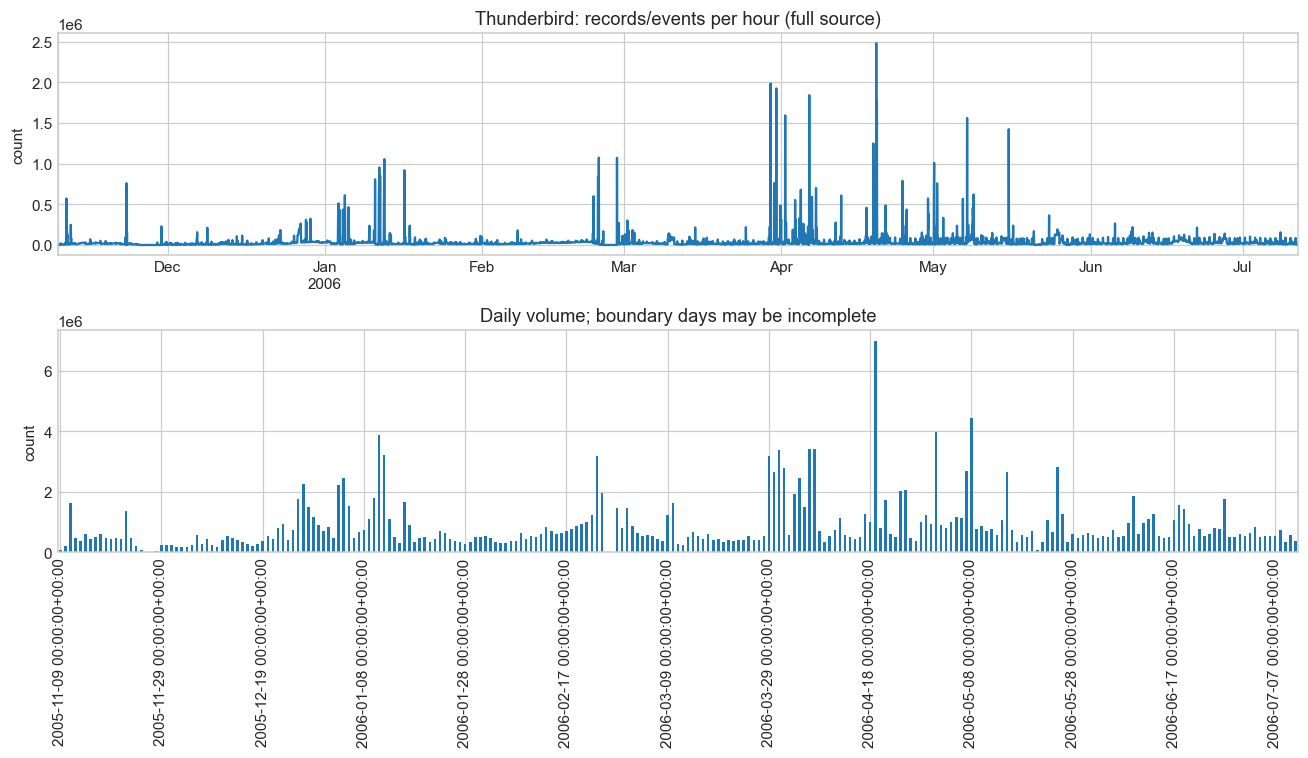

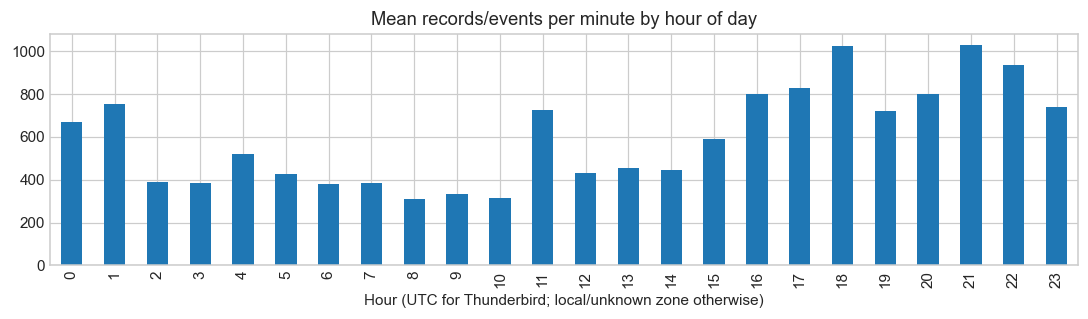

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
dense["count"].resample("1h").sum().plot(ax=axes[0], title=f"{NAME}: records/events per hour (full source)")
dense["count"].resample("1D").sum().plot.bar(ax=axes[1], title="Daily volume; boundary days may be incomplete")
axes[1].set_xticks(axes[1].get_xticks()[::max(1, len(dense.resample("1D").sum()) // 12)])
for ax in axes:
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 3))
dense.groupby(dense.index.hour)["count"].mean().plot.bar(ax=ax, title="Mean records/events per minute by hour of day")
ax.set_xlabel("Hour (UTC for Thunderbird; local/unknown zone otherwise)")
plt.tight_layout()
plt.show()

In [8]:
for column in ["component", "host", "level"]:
    display(Markdown(f"**{column}: частоты и изменение долей ({SCOPE})**"))
    display(distribution(events, column).head(12))
    changes, tvd = drift(events, column)
    display({"total_variation_distance": tvd})
    display(changes.head(8))

display(pd.Series(source["hosts"]).sort_values(ascending=False).head(15).to_frame("host_count_full_stream"))

**component: частоты и изменение долей (100 000 случайных физических строк; глобальная интенсивность по всему файлу)**

,count,fraction
component,,
kernel,38709,0.387098
sshd,7276,0.072761
xinetd,5655,0.056551
ib_sm,5598,0.055981
crond(pam_unix),5423,0.054231
ntpd,5310,0.053101
postfix/postdrop,4993,0.049931
ib_sm.x,3382,0.033821
crond,3148,0.031481


{'total_variation_distance': 0.257938920337762}

period,first_half,second_half,delta
component,,,
postfix/postdrop,0.103617,0.012657,-0.090960
ib_sm.x,0.082215,0.000220,-0.081995
sshd,0.030675,0.101982,0.071307
kernel,0.353482,0.410437,0.056955
xinetd,0.035116,0.071433,0.036317
snmpd,0.037044,0.017892,-0.019152
time.c,0.000000,0.018739,0.018739
ntpd,0.044512,0.059065,0.014553


**host: частоты и изменение долей (100 000 случайных физических строк; глобальная интенсивность по всему файлу)**

,count,fraction
host,,
tbird-sm1,8415,0.084152
tsqe2,4509,0.045091
an538,2083,0.020830
#9#,1297,0.012970
an690,925,0.009250
cn650,866,0.008660
cn551,861,0.008610
bn971,848,0.008480
tbird-sm2,713,0.007130


... (3 outputs left out)

,count,fraction
level,,
<missing>,99998,1.0


{'total_variation_distance': 0.0}

period,first_half,second_half,delta
level,,,
<missing>,1.0,1.0,0.0


,host_count_full_stream
tbird-sm1,17636106
tsqe2,9617213
an538,4266931
#9#,2853778
an690,1961657
bn971,1832356
cn650,1828764
cn551,1822505
tbird-admin1,1504733
en228,1478711


## 6. Сообщения

Длины измеряем в символах Unicode. Выброс — выше Q3 + 1,5×IQR, это статистическое правило, а не метка аномалии. Слова: латинские буквенные токены длиной от двух символов, lowercase, без stop-word фильтра. Биграммы не пересекают границы сообщений. Редкие токены и сообщения сохраняют параметры, поэтому их редкость ещё не означает новое поведение. Ссылки на компоненты ищем среди 20 наиболее активных имён; совпадение текста не устанавливает сетевую зависимость.

,message_characters
count,99998.000000
mean,79.072661
std,71.584372
min,0.000000
1%,16.000000
50%,47.000000
90%,219.000000
95%,245.000000
99%,272.000000
max,1011.000000


{'IQR_cutoff': 150.5, 'outlier_events': 14635}

,line_no,message_length,message
134398,177977734,1011,"RT::Handle=HASH(0x1929490) couldn't execute the query 'INSERT INTO ACL (PrincipalId, DelegatedFrom, RightName, ObjectId, PrincipalType, ..."
108575,123798157,615,Calling RRDs::update(/home/#26#/smokeping-2.0.7/etc/var/tbirdcoredevices/ibr5-southern.rrd --template uptime:loss:median:ping1:ping2:pin...
108599,123839568,615,Calling RRDs::update(/home/#26#/smokeping-2.0.7/etc/var/tbirdcoredevices/ibr1-southern.rrd --template uptime:loss:median:ping1:ping2:pin...
108641,123949688,615,Calling RRDs::update(/home/#26#/smokeping-2.0.7/etc/var/tbirdcoredevices/ibr3-southern.rrd --template uptime:loss:median:ping1:ping2:pin...
108793,124323080,615,Calling RRDs::update(/home/#26#/smokeping-2.0.7/etc/var/tbirdcoredevices/ibr5-southern.rrd --template uptime:loss:median:ping1:ping2:pin...


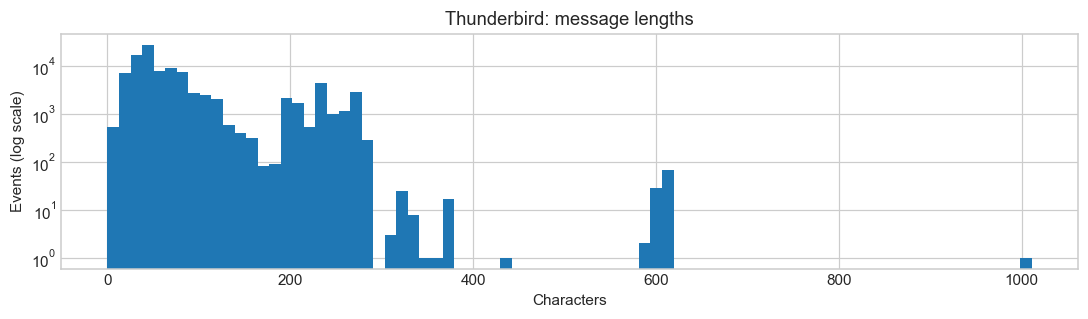

**words: самые частые и редкие**

,token,count
0,topspin,22172
1,src,22128
2,ib,15020
3,for,14004
4,from,12747
5,root,12587
6,file,11754
7,to,11728
8,thh,11583
9,user,11558


,token,count
2214,aaa,1
2215,aabdf,1
2216,aacf,1
2217,aadc,1
2218,aba,1
2219,abb,1
2220,abd,1
2221,abed,1
2222,abf,1
2223,abfaf,1


**bigrams: самые частые и редкие**

,token,count
0,src ib,13533
1,mnt_projects sysapps,11061
2,ib topspin,11060
3,sysapps src,11060
4,topspin topspin,11060
5,custom rhel,11059
6,obj_host_amd custom,11059
7,topspin src,11059
8,linux kernel,8000
9,src third_party,8000


,token,count
5114,aa ac,1
5115,aa ae,1
5116,aa bc,1
5117,aa ca,1
5118,aa eb,1
5119,aa lid,1
5120,aa mds,1
5121,aa size,1
5122,aa sock_alloc_inode,1
5123,aa was,1


... (2 outputs left out)

,count
message,
session opened for user root by (uid=0),4762
session closed for user root,2691
Got trap from peer on fd 13,2274
(root) CMD (run-parts /etc/cron.hourly),2228
THH(4): mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/third_party/thca4_linux/kernel/mlxhh/thh/obj_host_amd64_custom1_rhel4/mod_thh/tptm.c[1093]: alloc_reg_pages: Out of MTT entries,1737
THH(1): XHH_mrwm_register_mr: rc=HH_EAGAIN,1698
VIPKL(1): [MM_create_mr]:MM_mr_get_keys failed,1681
THH(1): mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/third_party/thca4_linux/kernel/mlxhh/thh/obj_host_amd64_custom1_rhel4/mod_thh/hob_comm.c[1597]: XHH_hob_process_local_mad: Device in FATAL state,1491
"[KERNEL_IB][tsIbTavorMadProcess][/mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/ib/tavor/provider/obj_host_amd64_custom1_rhel4/ts_ib_tavor/tavor_mad.c:152]InfiniHost0: EVAPI_process_local_mad failed, return code = -254 (Fatal error (Local Catastrophic Error))",1491


,count
singleton_message,
START: rsync pid=28899 from=10.100.0.65,1
Accepted publickey for #266# from ::ffff:10.100.32.1 port 32838 ssh2,1
START: rsync pid=606 from=10.100.18.81,1
START: rsync pid=29222 from=10.100.1.30,1
START: rsync pid=13499 from=10.100.28.35,1
START: rsync pid=29547 from=10.100.32.34,1
START: rsync pid=15012 from=10.100.28.48,1
START: rsync pid=754 from=10.100.31.115,1
74FE2864ABE: uid=50055 from=<#26#>,1


,count
message_seen_2_to_5,
"[ib_sm_discovery.c:1103]: Failed discover node test, node 5ad0000025a83, port_num= 9, error code 1",5
Kickstart: Configure sysctl parameters,5
My unqualified host name (aadmin1) unknown; sleeping for retry,5
[ib_sm_sweep.c:393]: IB node 00:05:ad:00:00:02:71:1e port 21 is INIT state,5
DHCPREQUEST on eth0 to #342# port 67,5
failed,5
[ib_sm_sweep.c:393]: IB node 00:05:ad:00:00:02:a4:66 port 6 is INIT state,5
"[ib_sm_discovery.c:490]: Failed to GetNodeInfo() - hop_count: 6, direct_path: 0, 1, 2, 13, 11, 1, 9, 0, 0, 0",5
"MOSAL(1): mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/third_party/thca4_linux/kernel/mlxsys/obj_host_amd64_custom1_rhel4/mlxsys/mosal_mem.c[422]: MOSAL_virt_to_phys_ex: cannot retrieve pmd_p: prot_ctx=USER, va=0x2C005F3000",5


,producer,mentioned_component,events
0,kernel,time.c,272
1,sysctl,kernel,197
2,ntpd,kernel,149
3,rc.sysinit,kernel,51
4,kernel,MDT,46
5,pbs_mom.real,pbs_mom,28
6,date,MDT,17
7,instsvcdrv,kernel,12
8,rc.sysinit,MDT,12
9,modprobe,kernel,6


In [9]:
text_stats = message_statistics(events)
display(text_stats["lengths"].to_frame("message_characters"))
display({"IQR_cutoff": text_stats["outlier_cutoff_IQR"], "outlier_events": text_stats["outliers"]})
display(events.nlargest(5, "message_length")[["line_no", "message_length", "message"]])
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(events.message_length, bins=80, log=True)
ax.set(title=f"{NAME}: message lengths", xlabel="Characters", ylabel="Events (log scale)")
plt.tight_layout()
plt.show()
for kind in ["words", "bigrams"]:
    display(Markdown(f"**{kind}: самые частые и редкие**"))
    display(text_stats[kind].head(12))
    display(text_stats[kind].sort_values(["count", "token"]).head(12))
characters = text_stats["characters"].to_frame("characters")
characters["fraction"] = characters.characters / characters.characters.sum()
display(characters)
display(text_stats["frequency_bands"].to_frame("unique_message_count"))
display(text_stats["messages"].head(10).rename_axis("message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.eq(1)].head(10).rename_axis("singleton_message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.between(2, 5)].head(10).rename_axis("message_seen_2_to_5").to_frame("count"))
display(component_mentions(events))

## 7. Сущности и кандидаты в сессии

Регулярные выражения выделяют IPv4/IPv6, порты, UUID, пути, URL, кандидаты в хэши и устройства, явные session ID. Синтаксис IP проверяется через `ipaddress`, порты ограничены 0–65535. Даже корректная по форме последовательность может оказаться частью другого идентификатора; это не подтверждение сетевой роли сущности. Пути, хэши и устройства — **кандидаты**, а не подтверждённые типы: 32 hex-символа могут быть ID, `/10.0.0.1` — адресом, а не путём. Классы могут пересекаться; их суммы нельзя складывать как число сущностей. Ищем в сообщениях, без полей заголовка.

ZooKeeper: явный `session id 0x…`. OpenSSH: `(host, PID, сегмент активности с разрывом >30 минут)` — эвристика, PID переиспользуется и не равен ID соединения. Для Mac и Thunderbird универсальный session ID не заявляем.

In [10]:
entities, entity_examples = entity_counts(events)
display(entities)
for kind, examples in entity_examples.items():
    display(Markdown(f"**{kind}: примеры и число упоминаний**"))
    display(examples)
sessions = session_candidates(events, NAME)
display({"candidate_sessions": len(sessions)})
display(sessions.head(10))

,unique,mentions,events_with_entity
entity,,,
ipv4,3179,13244,12562
ipv6,1003,5855,5232
port,2227,7349,6688
uuid,0,0,0
path,232,9788,8547
url,2,44,44
hash_candidate,0,0,0
device_candidate,90,3168,2922
session_id,414,415,415


**ipv4: примеры и число упоминаний**

,value,mentions
0,10.100.24.250,500
1,10.100.26.250,486
2,10.100.28.250,484
3,10.100.10.250,463
4,10.100.14.250,460
5,10.100.30.250,445
6,10.100.12.250,439
7,10.100.8.250,427
8,10.100.16.250,389
9,10.100.18.250,370


**ipv6: примеры и число упоминаний**

,value,mentions
0,::ffff:10,2213
1,::,100
2,0:5:ad::2:78:56,37
3,0:5:ad::2:70:aa,29
4,0:5:ad::2:71:1e,27
5,0:5:ad::2:8b:cd,27
6,0:5:ad::2:89:c6,26
7,0:5:ad::2:75:96,25
8,0:5:ad::2:7a:62,24
9,0:5:ad::2:a4:66,22


**port: примеры и число упоминаний**

... (11 outputs left out)

**session_id: примеры и число упоминаний**

,value,mentions
0,0x100b15ea980,2
1,0x10042dd3900,1
2,0x10087be4800,1
3,0x1019acef740,1
4,0x10074c49240,1
5,0x10080350d80,1
6,0x1002df1cb80,1
7,0x1018e2f2980,1
8,0x100b126c580,1
9,0x1016ca70740,1


{'candidate_sessions': 0}

,events,first,last,duration_seconds


## 8. Шаблоны событий

Используем [Drain3](https://github.com/logpai/Drain3), `depth=4`, `sim_th=0.4`, с масками UUID/IP/HEX/NUM. Обучаем на текстах сообщений в порядке файла, без времён и labels. Для каждого cluster ID показываем **финальный** шаблон, потому что при обучении он обобщается. Это исследовательская кластеризация, не оценка точности парсинга. Время первого/последнего наблюдения и число дней не доказывают рождение/исчезновение события вне периода наблюдения. Для Thunderbird это особенно существенно: редкий шаблон мог не попасть в выборку.

{'templates': 1068, 'singleton_templates': 260}

,count,template,first,last,observed_days
template_id,,,,,
641,4991,warning: mail_queue_enter: create file maildrop/<NUM>.<NUM>: Read-only file system,2006-01-22 12:47:42+00:00,2006-06-20 16:51:05+00:00,57
26,4896,session opened for user <*> by <*>,2005-11-10 11:01:01+00:00,2006-07-11 14:54:53+00:00,238
375,4466,MOSAL(<NUM>): <*> = <*>,2005-11-24 00:06:51+00:00,2006-07-10 18:11:32+00:00,46
1,4358,synchronized to <*> stratum <NUM>,2005-11-09 19:10:50+00:00,2006-07-11 16:26:07+00:00,224
23,3630,START: <*> pid=<NUM> from=<IP>,2005-11-10 01:28:21+00:00,2006-07-11 11:32:54+00:00,181
24,2797,session closed for user <*>,2005-11-10 06:01:01+00:00,2006-07-11 15:13:13+00:00,234
229,2390,(root) CMD <*> <*>,2005-11-14 20:01:01+00:00,2006-07-11 13:01:01+00:00,232
149,2275,Got trap from peer on fd <NUM>,2005-11-11 01:21:56+00:00,2006-07-11 04:37:30+00:00,208
29,2251,Accepted <*> for <*> from <*> port <NUM> ssh2,2005-11-10 19:03:05+00:00,2006-07-11 16:30:14+00:00,208


,count,template,first,last,observed_days
template_id,,,,,
666,1,#<NUM># : TTY=pts/<NUM> ; PWD=/home/#<NUM># ; USER=root ; COMMAND=/bin/chmod <NUM> /apps/contrib/showmesh,2006-02-02 23:19:33+00:00,2006-02-02 23:19:33+00:00,1
948,1,%RPM1-P:CP %LACP-<NUM>-PORT-GROUPED: PortChannel-<NUM>-Grouped: Interface Gi <NUM>/<NUM> joined port-channel <NUM>,2006-04-28 02:40:23+00:00,2006-04-28 02:40:23+00:00,1
904,1,"(#<NUM>#) CMD (/home/#<NUM>#/ping2.sh | mail -s ""Ping Tests"" #<NUM>#@#<NUM>#)",2006-04-07 18:25:01+00:00,2006-04-07 18:25:01+00:00,1
923,1,(#<NUM>#) CMD (echo `df -B GB | grep scratch3` `date --iso-<NUM>=minutes` >> $HOME/dflog/t-scr3-dflog.txt),2006-04-14 13:00:03+00:00,2006-04-14 13:00:03+00:00,1
660,1,(dcc_check_client) connection from <IP>:<NUM>,2006-01-31 22:43:37+00:00,2006-01-31 22:43:37+00:00,1
654,1,"(dcc_log_daemon_started) inetd server started (<NUM>.<NUM>.<NUM> x86_64-redhat-linux-gnu, built Mar <NUM> <NUM> <NUM>:<NUM>:<NUM>)",2006-01-31 21:23:33+00:00,2006-01-31 21:23:33+00:00,1
659,1,"(dcc_r_file_timed) <NUM> bytes received in <NUM>.000411s, rate 236955kB/s",2006-01-31 22:40:55+00:00,2006-01-31 22:40:55+00:00,1
952,1,(root) CMD (ssh tbird-sm1 /home/#<NUM>#/SCRIPTS/counters.cron1 ),2006-04-30 13:26:01+00:00,2006-04-30 13:26:01+00:00,1
1013,1,-- root[<NUM>]: ROOT LOGIN ON tty1,2006-05-26 18:02:36+00:00,2006-05-26 18:02:36+00:00,1


,count,template,first,last,observed_days
template_id,,,,,
1,4358,synchronized to <*> stratum <NUM>,2005-11-09 19:10:50+00:00,2006-07-11 16:26:07+00:00,224
2,694,data_thread() got not answer from any <*> datasource,2005-11-09 19:13:45+00:00,2006-07-10 18:32:43+00:00,108
3,11,Kickstart Install: <*> <*>,2005-11-09 19:56:29+00:00,2006-01-11 18:33:22+00:00,5
4,301,[ib_sm_sweep.c:<NUM>]: No configuration change required,2005-11-09 20:07:18+00:00,2006-07-11 10:09:48+00:00,142
5,604,[ib_sm_sweep.c:<NUM>]: No <*> <*>,2005-11-09 20:28:05+00:00,2006-07-11 08:39:48+00:00,208
6,1,"PCI interrupt <NUM>:<NUM>:<NUM>.<NUM>[A] -> GSI <NUM> (level, low) -> IRQ <NUM>",2005-11-09 20:38:29+00:00,2005-11-09 20:38:29+00:00,1
7,46,Linux version <*> (#<NUM>#@#<NUM>#) (gcc version <NUM>.<NUM>.<NUM> <NUM> (Red Hat <NUM>.<NUM>.<NUM>-<NUM>.<NUM>)) #<NUM> SMP Tue <*> <NU...,2005-11-09 22:11:49+00:00,2006-05-17 21:12:35+00:00,25
8,44,"HighMem zone: <NUM> pages, LIFO batch:<NUM>",2005-11-09 22:31:07+00:00,2006-05-15 21:42:59+00:00,27
9,3,"[ib_sm_bringup.c:<NUM>]: Active port(s) now in INIT state node=<HEX>, port=<NUM>, state=<NUM>, neighbor node=<HEX>, port=<NUM>, state=<NUM>",2005-11-09 22:39:52+00:00,2006-02-10 16:49:39+00:00,3


,count,template,first,last,observed_days,days_since_last
template_id,,,,,,
6,1,"PCI interrupt <NUM>:<NUM>:<NUM>.<NUM>[A] -> GSI <NUM> (level, low) -> IRQ <NUM>",2005-11-09 20:38:29+00:00,2005-11-09 20:38:29+00:00,1,243.846655
10,1,gmetad startup succeeded,2005-11-09 22:41:14+00:00,2005-11-09 22:41:14+00:00,1,243.761412
18,1,"[ib_sm_bringup.c:<NUM>]: Skip node= 5ad0000027df8, port= <NUM> bringup because topology is stale, no response",2005-11-09 23:33:48+00:00,2005-11-09 23:33:48+00:00,1,243.724907
106,1,/tmp1:,2005-11-11 01:18:54+00:00,2005-11-11 01:18:54+00:00,1,242.651921
139,1,megaraid: fw version:[521S] bios version:[H430],2005-11-11 01:19:50+00:00,2005-11-11 01:19:50+00:00,1,242.651273
162,1,System clock time adjusted to the past. Resetting next wakeup time.,2005-11-11 01:45:07+00:00,2005-11-11 01:45:07+00:00,1,242.633715
176,8,Unable to write meta data for metric <*> to RRD,2005-11-11 04:14:13+00:00,2005-11-11 08:09:17+00:00,1,242.366933
177,10,RRD_update <*> opening <*> Too many open files in system,2005-11-11 04:40:08+00:00,2005-11-11 08:10:41+00:00,1,242.365961
175,73,file-max limit <NUM> reached,2005-11-11 04:11:00+00:00,2005-11-11 08:12:53+00:00,1,242.364433


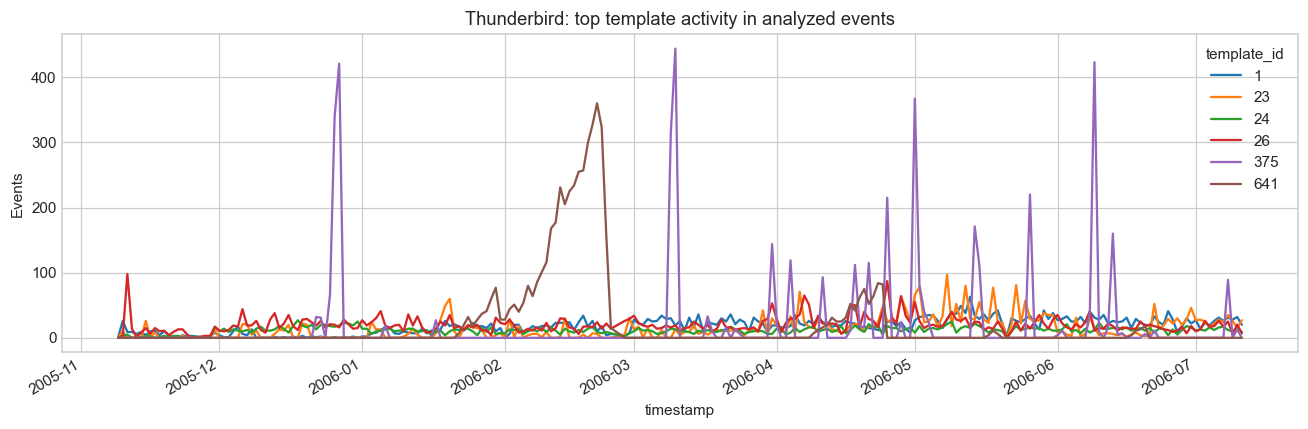

In [11]:
events, templates = mine_templates(events)
assert templates["count"].sum() == len(events)
display({"templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum())})
display(templates.head(12))
display(templates.sort_values(["count", "template"]).head(12))
display(templates.sort_values("first").head(10))
observation_end = events.timestamp.max()
template_inactivity = templates.assign(days_since_last=(observation_end - templates["last"]).dt.total_seconds() / 86400)
display(template_inactivity.sort_values("days_since_last", ascending=False).head(10))
top_ids = templates.head(6).index
activity = events.loc[events.template_id.isin(top_ids)].groupby([pd.Grouper(key="timestamp", freq="1D"), "template_id"]).size().unstack(fill_value=0)
activity.plot(figsize=(12, 4), title=f"{NAME}: top template activity in analyzed events")
plt.ylabel("Events")
plt.tight_layout()
plt.show()

## 9. Разметка и аномалии

Размечена **каждая строка Thunderbird**: `-` — non-alert, прочие значения — alert-категории. Это не сессионная и не оконная разметка. Оконные метки ниже производны: окно alert-positive, если содержит хотя бы одну alert-строку. Полные доли и кластеры активности берём из сканирования всего файла. Сравнение длин, производителей и шаблонов выполняется на равновероятной выборке; редкие классы могут быть представлены слабо. «Только в alert» означает лишь наблюдение в этой выборке, поэтому отдельно вводим поддержку ≥5.

Для ручного чтения выбираем сначала разные тексты alert. Если их меньше десяти, дополняем другими размеченными строками с повторяющимся текстом. Это десять строк, а не десять независимо подтверждённых инцидентов.

,full_stream_lines
-,207963953
VAPI,3229194
PBS_CON,5318
MPT,4583
EXT_FS,4022
CPU,2741
SCSI,2186
ECC,146
PBS_BFD,28
CHK_DSK,13


{'full_alert_lines': 3248239,
 'full_alert_fraction': 0.01537903171801749,
 'sample_alert_fraction': 0.01502030040600812,
 'longest_consecutive_alert_run_in_file': 169}

,lines,mean_length,median_length,hosts
is_anomaly,,,,
False,98496,76.181429,46.0,5132
True,1502,268.669774,270.0,133


is_anomaly,False,True
component,,
kernel,0.377792,0.997337
<missing>,0.031819,0.001332
pbs_mom,0.004559,0.001332
/usr/sbin/gmetad,0.002518,0.000000
<ffffffffa0582ab0>{,0.000010,0.000000
<ffffffffa00a65ef>{,0.000010,0.000000
CPU,0.000010,0.000000
CROND,0.000264,0.000000
MDT,0.006660,0.000000


is_anomaly,False,True
host,,
an690,0.006406,0.195739
dn30,0.002437,0.088549
dn825,0.002660,0.077230
bn971,0.007574,0.067909
en384,0.000761,0.028628
en256,0.000863,0.027297
en251,0.000721,0.024634
en382,0.000731,0.023302
en275,0.001553,0.022636


is_anomaly,False,True
level,,
<missing>,1.0,1.0


,normal,alert,template
template_id,,,
180,0,1491,[KERNEL_IB][tsIbTavorMadProcess][/mnt_projects/sysapps/src/ib/topspin/topspin-src-<NUM>.<NUM>.<NUM>-<NUM>/ib/tavor/provider/obj_host_amd...


,normal,alert,template
template_id,,,
641,4991,0,warning: mail_queue_enter: create file maildrop/<NUM>.<NUM>: Read-only file system
26,4896,0,session opened for user <*> by <*>
375,4466,0,MOSAL(<NUM>): <*> = <*>
1,4358,0,synchronized to <*> stratum <NUM>
23,3630,0,START: <*> pid=<NUM> from=<IP>
24,2797,0,session closed for user <*>
229,2390,0,(root) CMD <*> <*>
149,2275,0,Got trap from peer on fd <NUM>
29,2251,0,Accepted <*> for <*> from <*> port <NUM> ssh2


{'alert_positive_minutes': 70560, 'alert_minute_runs': 1965}

,start,end_exclusive,active_minutes,alerts,all_records
153,2005-12-19 16:27:00+00:00,2006-01-03 14:21:00+00:00,21474,1160650,13770484
1907,2006-06-27 00:46:00+00:00,2006-06-27 20:26:00+00:00,1180,355171,1632674
1891,2006-06-18 12:03:00+00:00,2006-06-19 21:44:00+00:00,2021,313764,2232409
1889,2006-06-17 03:12:00+00:00,2006-06-18 09:38:00+00:00,1826,247730,1428260
14,2005-11-13 13:44:00+00:00,2005-11-14 18:42:00+00:00,1738,115693,718808
15,2005-11-15 14:06:00+00:00,2005-11-18 21:46:00+00:00,4780,111418,1763636
294,2006-01-13 19:21:00+00:00,2006-01-17 15:38:00+00:00,5537,104237,3176148
16,2005-11-18 21:55:00+00:00,2005-11-21 15:27:00+00:00,3932,92578,1232540
1874,2006-06-12 22:48:00+00:00,2006-06-13 03:01:00+00:00,253,82028,382729
731,2006-03-04 14:33:00+00:00,2006-03-06 16:17:00+00:00,2984,65987,1169337


,count,mean,std,min,25%,50%,75%,max
alert_positive,,,,,,,,
False,281681.0,587.262787,3479.303172,0.0,108.0,198.0,331.0,205034.0
True,70560.0,648.971414,2299.413119,1.0,219.0,319.0,492.0,118362.0


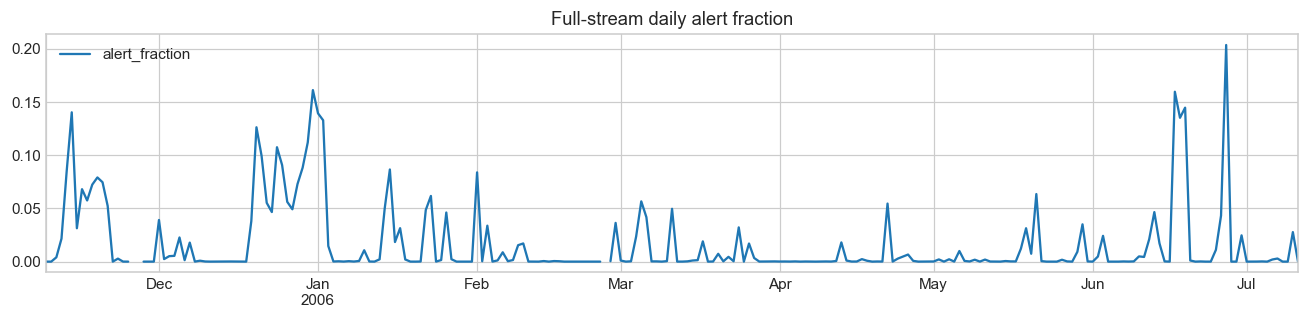

,line_no,timestamp,label,component,message
50600,1191224,2005-11-11 05:54:16+00:00,VAPI,kernel,"[KERNEL_IB][tsIbTavorMadProcess][/mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/ib/tavor/provider/obj_host_amd64_custom1_rhel4/ts_ib_tavor/tavor_mad.c:152]InfiniHost0: EVAPI_process_local_mad failed, return code = -254 (Fatal error (Local Catastrophic Error))"
66879,35552526,2006-01-07 15:17:10+00:00,MPT,kernel,mptscsih: ioc0: attempting task abort! (sc=000001002359cd80)
74121,50886815,2006-01-18 01:55:44+00:00,EXT_FS,kernel,EXT3-fs error (device sda5) in start_transaction: Journal has aborted
78550,60208807,2006-02-08 17:36:31+00:00,CPU,kernel,Losing some ticks... checking if CPU frequency changed.
93390,91403393,2006-03-22 20:29:57+00:00,PBS_CON,pbs_mom,"Connection refused (111) in open_demux, open_demux: cannot connect to 10.100.30.42:45537"
96119,97372007,2006-03-30 03:09:32+00:00,ECC,None,Server Administrator: Instrumentation Service EventID: 1404 Memory device status is critical Memory device location: DIMM1_B Possible memory module event cause:Single bit error logging disabled
126974,162421201,2006-05-09 23:19:08+00:00,PBS_CON,pbs_mom,"Connection refused (111) in open_demux, open_demux: cannot connect to 10.100.34.124:35340"
127813,164244901,2006-05-12 11:03:35+00:00,MPT,kernel,mptscsih: ioc0: attempting task abort! (sc=000001007172fd00)
146429,203591477,2006-06-28 07:17:07+00:00,ECC,None,Server Administrator: Instrumentation Service EventID: 1404 Memory device status is critical Memory device location: DIMM2_A Possible memory module event cause:Single bit error logging disabled
50603,1193825,2005-11-11 05:58:54+00:00,VAPI,kernel,"[KERNEL_IB][tsIbTavorMadProcess][/mnt_projects/sysapps/src/ib/topspin/topspin-src-3.2.0-16/ib/tavor/provider/obj_host_amd64_custom1_rhel4/ts_ib_tavor/tavor_mad.c:152]InfiniHost0: EVAPI_process_local_mad failed, return code = -254 (Fatal error (Local Catastrophic Error))"


Эпизод здесь — последовательность соседних минут с хотя бы одним alert. Это длительность занятых минутных ячеек, не длительность отказа; погрешность границ до минуты, а одновременные инциденты могут смешиваться. Примеры позволяют проверить смысл alert, но не независимую истинность разметки.

In [12]:
labels_full = pd.Series(source["labels"]).sort_values(ascending=False)
display(labels_full.to_frame("full_stream_lines"))
alert_total = int(labels_full.drop("-", errors="ignore").sum())
display({"full_alert_lines": alert_total, "full_alert_fraction": alert_total / source["physical_lines"], "sample_alert_fraction": float(events.is_anomaly.mean()), "longest_consecutive_alert_run_in_file": source["longest_alert_run_file_order"]})
display(events.groupby("is_anomaly").agg(lines=("message", "size"), mean_length=("message_length", "mean"), median_length=("message_length", "median"), hosts=("host", "nunique")))
for column in ["component", "host", "level"]:
    display(pd.crosstab(events[column].fillna("<missing>"), events.is_anomaly, normalize="columns").sort_values(True, ascending=False).head(15))
label_templates = pd.crosstab(events.template_id, events.is_anomaly).reindex(columns=[False, True], fill_value=0)
label_templates.columns = ["normal", "alert"]
label_templates = label_templates.join(templates[["template"]])
display(label_templates.loc[label_templates.normal.eq(0) & label_templates.alert.ge(5)].sort_values("alert", ascending=False).head(10))
display(label_templates.loc[label_templates.alert.eq(0) & label_templates.normal.ge(5)].sort_values("normal", ascending=False).head(10))
episodes = alert_episodes(minutes)
display({"alert_positive_minutes": int(dense.alerts.fillna(0).gt(0).sum()), "alert_minute_runs": len(episodes)})
display(episodes.head(10))
display(dense.assign(alert_positive=dense.alerts.fillna(0).gt(0)).groupby("alert_positive")["count"].describe())
daily = dense[["count", "alerts"]].resample("1D").sum()
daily["alert_fraction"] = daily.alerts / daily["count"].replace(0, np.nan)
daily[["alert_fraction"]].plot(title="Full-stream daily alert fraction", figsize=(12, 3))
plt.tight_layout()
plt.show()
alert_rows = events.loc[events.is_anomaly.fillna(False)]
examples = alert_rows.drop_duplicates("message").head(10)
if len(examples) < 10:
    examples = pd.concat([examples, alert_rows.loc[~alert_rows.index.isin(examples.index)].head(10 - len(examples))])
assert len(examples) == 10
assert examples.line_no.is_unique
with pd.option_context("display.max_colwidth", None):
    display(examples[["line_no", "timestamp", "label", "component", "message"]])
display(Markdown("Эпизод здесь — последовательность соседних минут с хотя бы одним alert. Это длительность занятых минутных ячеек, не длительность отказа; погрешность границ до минуты, а одновременные инциденты могут смешиваться. Примеры позволяют проверить смысл alert, но не независимую истинность разметки."))

## 10. Временные окна

Сравниваем фиксированные непересекающиеся окна 1, 5, 15, 60 минут и сутки. Сетка покрывает весь наблюдаемый период, нулевые окна сохраняются. Крайние окна частичны. `above_p99` — разведочный индикатор концентрации; p99 не является порогом доказанной аномалии. Дисперсия/среднее описывает неравномерность нагрузки, но без стационарности не служит тестом на аномалии.

Для Thunderbird используются **точные полные поминутные агрегаты**, а не прореженная выборка. Таким образом, пустые минуты не создаются процедурой sampling.

,windows,empty,empty_fraction,mean,median,p99,max,above_p99,variance_over_mean
window_minutes,,,,,,,,,
1,352241,12288,0.034885,599.624098,221.0,5835.60,205034.0,3523,17911.767796
5,70449,2228,0.031626,2998.086446,1242.0,31469.36,544089.0,705,61294.296506
15,23484,679,0.028913,8993.876341,4305.0,93004.24,1204085.0,235,126306.780318
60,5871,153,0.026060,35975.505365,18253.0,415848.50,2478538.0,59,269623.197799
1440,245,3,0.012245,862090.579592,558481.0,3925234.04,6980098.0,3,844664.612052


,count,alerts
2006-03-29 22:10:00+00:00,205034.0,0.0
2006-04-07 02:06:00+00:00,199282.0,0.0
2006-05-01 04:02:00+00:00,191049.0,0.0
2006-04-07 01:27:00+00:00,190662.0,0.0
2006-04-01 19:24:00+00:00,174477.0,0.0
2006-05-15 21:43:00+00:00,170905.0,0.0
2006-03-15 01:32:00+00:00,169942.0,0.0
2006-04-06 13:37:00+00:00,167540.0,0.0
2005-11-11 01:19:00+00:00,158428.0,0.0
2006-04-06 13:47:00+00:00,153480.0,0.0


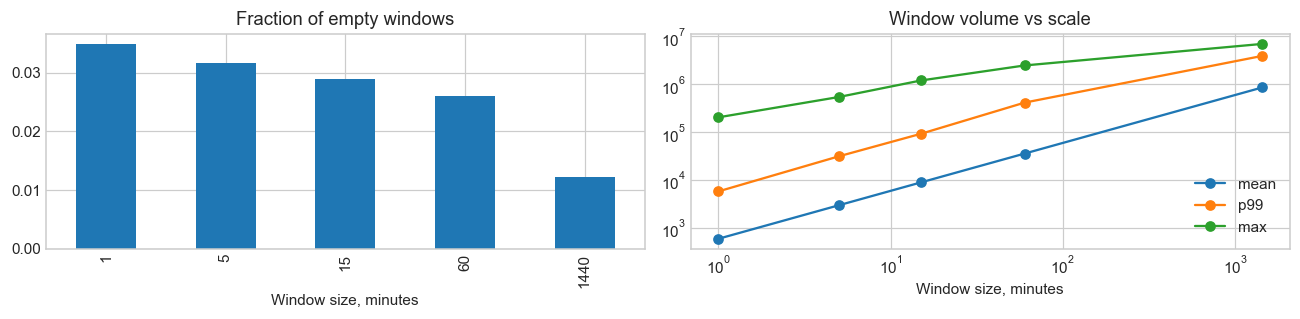

In [13]:
windows = window_summary(minutes)
display(windows)
display(dense.nlargest(10, "count"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
windows.empty_fraction.plot.bar(ax=axes[0], title="Fraction of empty windows")
windows[["mean", "p99", "max"]].plot(ax=axes[1], marker="o", logy=True, logx=True, title="Window volume vs scale")
axes[0].set_xlabel("Window size, minutes")
axes[1].set_xlabel("Window size, minutes")
plt.tight_layout()
plt.show()

## 11. Проверяемый дайджест и открытые вопросы

Следующая ячейка собирает ключевые числа из текущего запуска. В финальной Markdown-ячейке — их интерпретация и ограничения.

In [14]:
digest = {
        "dataset": NAME,
        "physical_lines_full": int(source["physical_lines"]),
        "analyzed_events": len(events),
        "parse_fraction_physical": float(physical.parse_ok.mean()),
        "duplicates_in_analyzed_physical": int(physical.raw.duplicated().sum()),
        "multiline_events": int(events.physical_line_count.gt(1).sum()),
        "start": str(dense.index.min()), "end": str(dense.index.max()),
        "templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum()),
        "message_length_median": float(events.message_length.median()),
        "empty_minutes_fraction": float(windows.loc[1, "empty_fraction"]),
        "busiest_minute": str(dense["count"].idxmax()),
        "busiest_minute_count": int(dense["count"].max()),
        "top_component": str(events.component.value_counts().index[0]),
        "top_template": str(templates.iloc[0].template),
        "top_template_count": int(templates.iloc[0]["count"]),
        "entity_unique": {k: int(v) for k, v in entities["unique"].items()},
        "session_candidates": len(sessions),
        "unparsed_header_lines": int((physical.header_start & ~physical.parse_ok).sum()),
    }
digest["full_alert_lines"] = alert_total
digest["full_alert_fraction"] = alert_total / source["physical_lines"]
digest["sample_alert_lines"] = int(events.is_anomaly.sum())

display(JSON(digest))

<IPython.core.display.JSON object>

### Выводы по Thunderbird

- Полный источник: **211,212,192 физических строк**. Анализ текстов: **99,998 событий**.
- Медиана длины сообщения — **47 символов**. Drain3 выделил **1068 шаблонов**, из них **260** встречаются один раз.
- На полной временной сетке **3.49% пустых минут**. Максимум — **205,034 событий/минуту**, 2006-03-29 22:10:00+00:00. Крайние окна частичны.

**Границы исследования.** Полностью просканировано 31 788 301 041 байт: все 211 212 192 строки имеют распознаваемое epoch-поле, пустых строк нет, 18 строк некорректны для UTF-8. Временные метки последовательны: 09.11.2005 08:05:01 — 11.07.2006 22:45:03 UTC. Глобальные объёмы, окна, alert-категории и значения host точные. Тексты, сущности и Drain3 исследованы на равновероятной выборке 100 000 строк (seed=42); две строки содержат заголовок без тела и оставлены в диагностике, поэтому текстовых событий 99 998. Ноль многострочных событий в этой выборке не доказывает их отсутствие во всём файле: разрозненные строки не склеивались.

**Время и качество.** В выборке 17 полных дубликатов сверх первого вхождения; глобальное число дублей не оценивалось. Преобладают разницы локального времени с UTC −8 и −7 часов, есть редкие смещения примерно на сутки. Это требует проверки полей даты и часов, а не автоматического присвоения timezone. Год локальной даты выбирался ближайшим к epoch, включая соседние годы. В заголовках 5 855 разных значений host, включая необычные технические имена; это не подтверждённое число физических машин. Пустые периоды, включая 5 216 минут подряд, без внешней телеметрии нельзя назвать простоем.

**Разметка.** В полном потоке 3 248 239 alert-строк (**1,5379%**); 3 229 194 из них — VAPI (**99,41% alerts**). В выборке 1 502 alert-строки. Средняя длина alert-сообщения около 269 символов против 76 у non-alert, но это в большой степени эффект доминирования одного повторяющегося VAPI-текста. Один Drain3-шаблон покрывает 1 491 sample-alert и не встречается среди sample-non-alert. Это наблюдаемая связь, не гарантия обобщения на новые виды отказов.

**Ручное чтение десяти размеченных строк.** В выборке только девять различных alert-текстов, поэтому десятый пример повторяет текст из другой строки. VAPI сообщает о Fatal/Local Catastrophic Error; EXT_FS — о прерванном журнале EXT3; ECC — о критическом статусе памяти; PBS_CON — об отказе соединения. MPT сообщает о попытке отмены SCSI-задачи, CPU — о потерянных тиках и проверке частоты. Смысл согласуется с категориями alert, но текст сам по себе не подтверждает фактический отказ или влияние на задания. Автоматически переносить метку на всю сессию/узел нельзя.

**Слабые места labels.** Наиболее частый шаблон в текстовой выборке — `Read-only file system` (4 991 строка), причём он встречается среди non-alert. Следовательно, опубликованная разметка отражает выбранные категории alerts, а не все возможные проблемы. Самая загруженная минута (205 034 строки) вообще не содержит alert-меток: всплеск объёма не равен размеченной аномалии. Выделено 1 965 серий соседних alert-положительных минут; они описывают активность меток, а не длительность инцидентов.

**Следующий шаг и открытые вопросы.** Какая полнота у alert-разметки и почему часть ошибок относится к non-alert? Какие редкие категории не попали в выборку? Что означают необычные host-значения и расхождения часов? Как связывать строку с заданием/сессией? Уникальные сущности и 1 068 шаблонов — наблюдения в выборке, не полные мощности словарей. Для будущей оценки нужно отдельно учитывать редкие категории и использовать разделение по времени/источникам; простая accuracy при таком дисбалансе будет малоинформативной.

**Воспроизводимость:** полный архив Zenodo с закреплённым MD5, контроль SHA-256, фиксированный seed, явные правила парсинга, версии библиотек в начале. Подсчёты соответствуют параметрам этого выполненного ноутбука. Все 11 пунктов чеклиста рассмотрены; ограничения разметки и неизвестные поля указаны явно.